In [1]:

# PROJECT 1: SME CREDIT RISK ANALYSIS

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 100)

print("Libraries imported successfully!")
print("SME Credit Risk Analysis - Project 1")


Libraries imported successfully!
SME Credit Risk Analysis - Project 1


In [2]:

# Create synthetic SME credit portfolio

data = {
    "Borrower": [
        "SME_001", "SME_002", "SME_003", "SME_004",
        "SME_005", "SME_006", "SME_007", "SME_008"
    ],

    "Sector": [
        "Agriculture", "Retail", "Manufacturing", "Trading",
        "Agriculture", "Services", "Retail", "Manufacturing"
    ],

    "Exposure_m": [8, 7, 6, 9, 5, 8, 6, 5],

    "Cashflow_m": [4.8, 3.6, 4.5, 3.0, 1.8, 5.2, 2.0, 3.4],

    "Debt_Service_m": [3.5, 3.0, 3.2, 3.5, 2.0, 4.0, 2.5, 3.0],

    "Arrears_Days": [0, 15, 0, 45, 95, 0, 120, 30]
}

# Convert dictionary into a DataFrame
df = pd.DataFrame(data)

# Display dataset
display(df)


,Borrower,Sector,Exposure_m,Cashflow_m,Debt_Service_m,Arrears_Days
0,SME_001,Agriculture,8,4.8,3.5,0
1,SME_002,Retail,7,3.6,3.0,15
2,SME_003,Manufacturing,6,4.5,3.2,0
3,SME_004,Trading,9,3.0,3.5,45
4,SME_005,Agriculture,5,1.8,2.0,95
5,SME_006,Services,8,5.2,4.0,0
6,SME_007,Retail,6,2.0,2.5,120
7,SME_008,Manufacturing,5,3.4,3.0,30


In [3]:

# Calculate Debt Service Coverage Ratio

df["DSCR"] = (
    df["Cashflow_m"] / df["Debt_Service_m"]
)

# Round results to two decimal places
df["DSCR"] = df["DSCR"].round(2)

# Display borrower and DSCR
display(df[["Borrower", "Cashflow_m",
            "Debt_Service_m", "DSCR"]])


,Borrower,Cashflow_m,Debt_Service_m,DSCR
0,SME_001,4.8,3.5,1.37
1,SME_002,3.6,3.0,1.20
2,SME_003,4.5,3.2,1.41
3,SME_004,3.0,3.5,0.86
4,SME_005,1.8,2.0,0.90
5,SME_006,5.2,4.0,1.30
6,SME_007,2.0,2.5,0.80
7,SME_008,3.4,3.0,1.13


In [4]:

# Classify borrowers requiring attention

df["Risk_Status"] = np.where(
    (df["DSCR"] < 1.20) |
    (df["Arrears_Days"] >= 30),
    "High Attention",
    "Performing"
)

display(
    df[["Borrower", "DSCR",
        "Arrears_Days", "Risk_Status"]]
)


,Borrower,DSCR,Arrears_Days,Risk_Status
0,SME_001,1.37,0,Performing
1,SME_002,1.20,15,Performing
2,SME_003,1.41,0,Performing
3,SME_004,0.86,45,High Attention
4,SME_005,0.90,95,High Attention
5,SME_006,1.30,0,Performing
6,SME_007,0.80,120,High Attention
7,SME_008,1.13,30,High Attention


In [5]:

# Calculate total credit exposure

total_exposure = df["Exposure_m"].sum()

print("Total Portfolio Exposure")
print(f"NGN {total_exposure:.2f} million")


Total Portfolio Exposure
NGN 54.00 million


In [6]:

# Simple average DSCR
average_dscr = df["DSCR"].mean()

# Exposure-weighted average DSCR
weighted_dscr = np.average(
    df["DSCR"],
    weights=df["Exposure_m"]
)

print("Average DSCR:", round(average_dscr, 3))
print("Weighted Average DSCR:", round(weighted_dscr, 3))


Average DSCR: 1.121
Weighted Average DSCR: 1.128


In [7]:

# Identify borrowers with 90+ days in arrears

npl_borrowers = df[
    df["Arrears_Days"] >= 90
]

# Calculate their total exposure
npl_exposure = npl_borrowers["Exposure_m"].sum()

# Calculate exposure ratio
npl_ratio = (
    npl_exposure / total_exposure
) * 100

print("90+ Day Arrears Exposure:")
print(f"NGN {npl_exposure:.2f} million")

print("90+ Day Arrears Exposure Ratio:")
print(f"{npl_ratio:.2f}%")

display(npl_borrowers)


90+ Day Arrears Exposure:
NGN 11.00 million
90+ Day Arrears Exposure Ratio:
20.37%


,Borrower,Sector,Exposure_m,Cashflow_m,Debt_Service_m,Arrears_Days,DSCR,Risk_Status
4,SME_005,Agriculture,5,1.8,2.0,95,0.9,High Attention
6,SME_007,Retail,6,2.0,2.5,120,0.8,High Attention


In [8]:

# Group credit exposure by economic sector

sector_analysis = (
    df.groupby("Sector")["Exposure_m"]
    .sum()
    .sort_values(ascending=False)
)

print("Credit Exposure by Sector")
display(sector_analysis)

# Calculate percentage contribution
sector_percentage = (
    sector_analysis / total_exposure
) * 100

print("Sector Contribution (%)")
display(sector_percentage.round(2))


Credit Exposure by Sector


,Exposure_m
Sector,
Agriculture,13
Retail,13
Manufacturing,11
Trading,9
Services,8


Sector Contribution (%)


,Exposure_m
Sector,
Agriculture,24.07
Retail,24.07
Manufacturing,20.37
Trading,16.67
Services,14.81


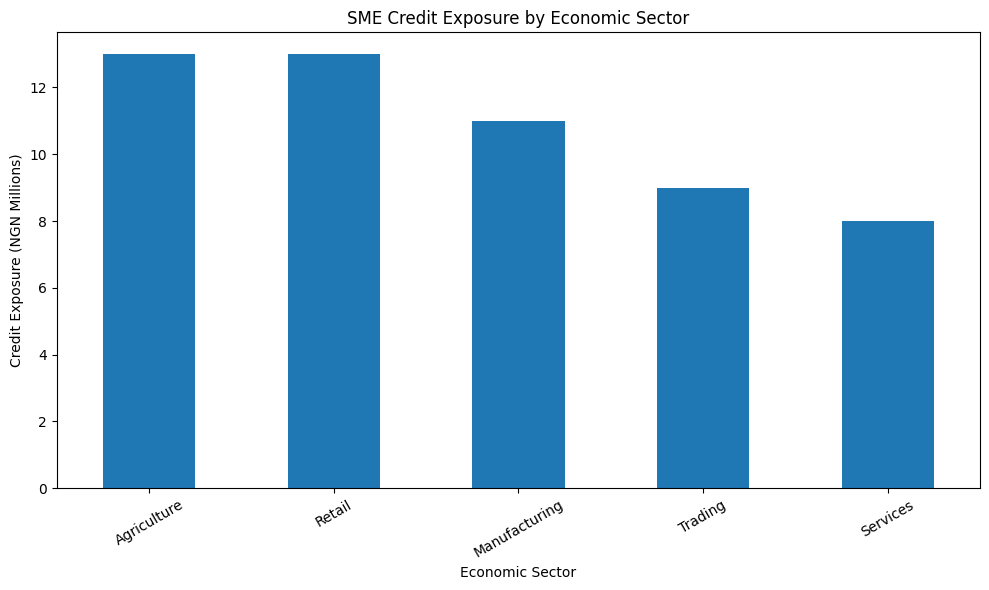

In [9]:

# Visualize sector credit exposure

plt.figure(figsize=(10, 6))

sector_analysis.plot(kind="bar")

plt.title("SME Credit Exposure by Economic Sector")
plt.xlabel("Economic Sector")
plt.ylabel("Credit Exposure (NGN Millions)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


In [10]:

# Import statistical analysis functions

from scipy import stats

print("SciPy statistical tools imported successfully!")


SciPy statistical tools imported successfully!


In [11]:

# Correlation between DSCR and arrears days

pearson_dscr = stats.pearsonr(
    df["DSCR"],
    df["Arrears_Days"]
)

# Correlation between exposure and arrears days

pearson_exposure = stats.pearsonr(
    df["Exposure_m"],
    df["Arrears_Days"]
)

print("DSCR vs Arrears Days")
print("Correlation:", round(pearson_dscr.statistic, 3))
print("P-value:", round(pearson_dscr.pvalue, 4))

print("\nExposure vs Arrears Days")
print("Correlation:", round(pearson_exposure.statistic, 3))
print("P-value:", round(pearson_exposure.pvalue, 4))


DSCR vs Arrears Days
Correlation: -0.899
P-value: 0.0024

Exposure vs Arrears Days
Correlation: -0.423
P-value: 0.296


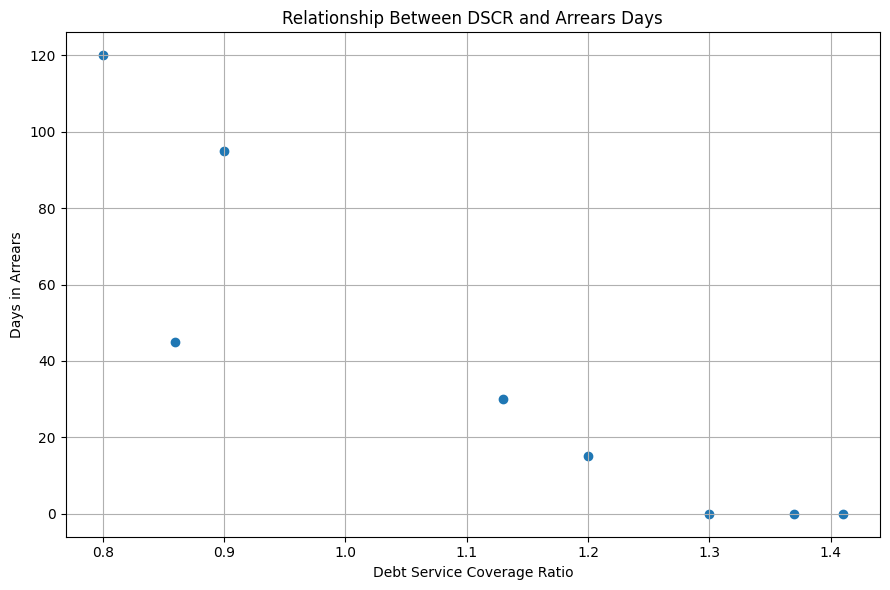

In [12]:

plt.figure(figsize=(9, 6))

plt.scatter(
    df["DSCR"],
    df["Arrears_Days"]
)

plt.title("Relationship Between DSCR and Arrears Days")
plt.xlabel("Debt Service Coverage Ratio")
plt.ylabel("Days in Arrears")

plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:

# Simple linear regression

regression = stats.linregress(
    df["DSCR"],
    df["Arrears_Days"]
)

print("REGRESSION RESULTS")
print("------------------")

print("Slope:", round(regression.slope, 3))
print("Intercept:", round(regression.intercept, 3))
print("R-squared:", round(regression.rvalue**2, 3))
print("P-value:", round(regression.pvalue, 4))


REGRESSION RESULTS
------------------
Slope: -173.022
Intercept: 232.125
R-squared: 0.809
P-value: 0.0024


In [14]:

from scipy import stats

# Significance level
alpha = 0.05

# Pearson correlation hypothesis test
r_value, p_value = stats.pearsonr(
    df["DSCR"],
    df["Arrears_Days"]
)

print("HYPOTHESIS TEST RESULTS")
print("-----------------------")

print("Pearson correlation:", round(r_value, 4))
print("P-value:", round(p_value, 4))
print("Significance level:", alpha)

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: Evidence of a nonzero linear correlation.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: Insufficient evidence of a nonzero linear correlation.")


HYPOTHESIS TEST RESULTS
-----------------------
Pearson correlation: -0.8994
P-value: 0.0024
Significance level: 0.05
Decision: Reject the null hypothesis.
Conclusion: Evidence of a nonzero linear correlation.


In [15]:

import statsmodels.api as sm

# Define independent variables
X = df[["DSCR", "Cashflow_m"]]

# Define dependent variable
y = df["Arrears_Days"]

# Add intercept
X = sm.add_constant(X)

# Fit multiple linear regression
model = sm.OLS(y, X).fit()

# Display regression summary
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:           Arrears_Days   R-squared:                       0.883
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     18.84
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00470
Time:                        10:40:30   Log-Likelihood:                -32.906
No. Observations:                   8   AIC:                             71.81
Df Residuals:                       5   BIC:                             72.05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        189.8023     41.254      4.601      0.0

In [16]:

# Examine relationships between independent variables

predictor_corr = df[["DSCR", "Cashflow_m"]].corr()

display(predictor_corr)


,DSCR,Cashflow_m
DSCR,1.000000,0.907812
Cashflow_m,0.907812,1.000000


In [17]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Independent variables without the intercept
X_vif = df[["DSCR", "Cashflow_m"]]

vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values, i
        )
        for i in range(X_vif.shape[1])
    ]
})

display(vif_results)


,Variable,VIF
0,DSCR,5.685795
1,Cashflow_m,5.685795


In [18]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Check correlation between the two predictors
predictor_corr = df[["DSCR", "Cashflow_m"]].corr()

print("Correlation between predictors:")
display(predictor_corr)

# Calculate VIF, including a constant in the design matrix
X_vif = sm.add_constant(df[["DSCR", "Cashflow_m"]])

vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Exclude the constant from the displayed results
vif_results = vif_results[vif_results["Variable"] != "const"]

print("Variance Inflation Factors:")
display(vif_results)

Correlation between predictors:


,DSCR,Cashflow_m
DSCR,1.000000,0.907812
Cashflow_m,0.907812,1.000000


Variance Inflation Factors:


,Variable,VIF
1,DSCR,5.685795
2,Cashflow_m,5.685795


In [19]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select regression predictors
X_vif = sm.add_constant(df[["DSCR", "Cashflow_m"]])

# Calculate VIF
vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_results[vif_results["Variable"] != "const"])

,Variable,VIF
1,DSCR,5.685795
2,Cashflow_m,5.685795


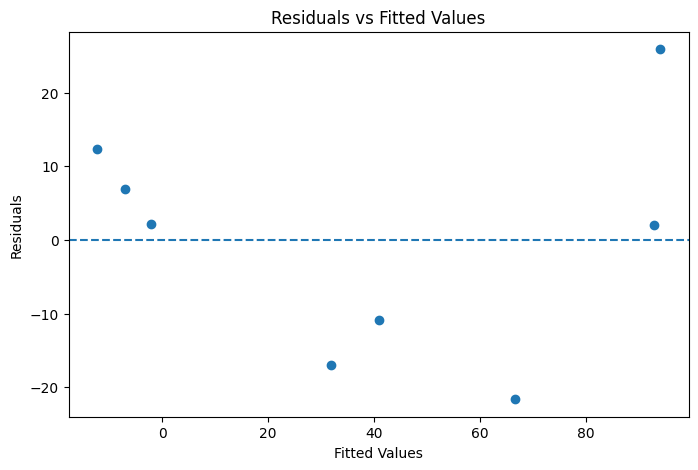

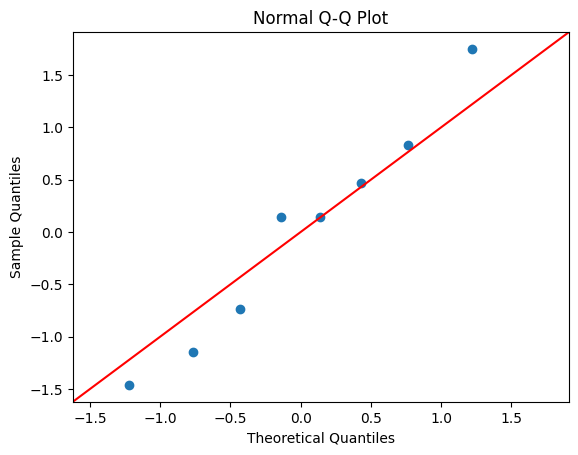

In [20]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Extract fitted values and residuals
fitted_values = model.fittedvalues
residuals = model.resid

# Plot 1: Residuals versus fitted values
plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.show()

# Plot 2: Normal Q-Q plot
sm.qqplot(residuals, line="45", fit=True)
plt.title("Normal Q-Q Plot")
plt.show()

In [21]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(residuals, model.model.exog)

labels = ["LM Statistic", "LM p-value",
          "F Statistic", "F p-value"]

for label, value in zip(labels, bp_test):
    print(f"{label}: {value:.4f}")

LM Statistic: 4.7743
LM p-value: 0.0919
F Statistic: 3.7002
F p-value: 0.1032


In [22]:
from statsmodels.stats.diagnostic import het_breuschpagan

residuals = model.resid
bp_test = het_breuschpagan(residuals, model.model.exog)

labels = [
    "LM Statistic",
    "LM p-value",
    "F Statistic",
    "F p-value"
]

for label, value in zip(labels, bp_test):
    print(f"{label}: {value:.4f}")

LM Statistic: 4.7743
LM p-value: 0.0919
F Statistic: 3.7002
F p-value: 0.1032


In [23]:
import statsmodels.api as sm

# Model 1: DSCR only
X1 = sm.add_constant(df[["DSCR"]])
model1 = sm.OLS(df["Arrears_Days"], X1).fit()

# Model 2: DSCR and Cashflow
X2 = sm.add_constant(df[["DSCR", "Cashflow_m"]])
model2 = sm.OLS(df["Arrears_Days"], X2).fit()

# Compare model performance
comparison = pd.DataFrame({
    "Metric": ["R-squared", "Adjusted R-squared", "AIC", "BIC"],
    "DSCR Only": [
        model1.rsquared,
        model1.rsquared_adj,
        model1.aic,
        model1.bic
    ],
    "Two Predictors": [
        model2.rsquared,
        model2.rsquared_adj,
        model2.aic,
        model2.bic
    ]
})

display(comparison.round(4))

,Metric,DSCR Only,Two Predictors
0,R-squared,0.8089,0.8828
1,Adjusted R-squared,0.7771,0.8360
2,AIC,73.7247,71.8120
3,BIC,73.8835,72.0503


In [24]:
# Compare the nested regression models
f_test = model2.compare_f_test(model1)

print("F-statistic:", round(f_test[0], 4))
print("P-value:", round(f_test[1], 4))
print("Degrees of freedom:", f_test[2])

F-statistic: 3.1541
P-value: 0.1359
Degrees of freedom: 1.0


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Generate predictions
df["Predicted_Arrears"] = model1.predict(
    sm.add_constant(df[["DSCR"]])
)

# Calculate prediction errors
df["Prediction_Error"] = (
    df["Arrears_Days"] - df["Predicted_Arrears"]
)

# Calculate performance metrics
mae = mean_absolute_error(
    df["Arrears_Days"],
    df["Predicted_Arrears"]
)

rmse = np.sqrt(mean_squared_error(
    df["Arrears_Days"],
    df["Predicted_Arrears"]
))

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))

display(df[
    ["Borrower", "Arrears_Days",
     "Predicted_Arrears", "Prediction_Error"]
].round(2))

Mean Absolute Error: 15.41
Root Mean Squared Error: 18.89


,Borrower,Arrears_Days,Predicted_Arrears,Prediction_Error
0,SME_001,0,-4.91,4.91
1,SME_002,15,24.50,-9.50
2,SME_003,0,-11.83,11.83
3,SME_004,45,83.33,-38.33
4,SME_005,95,76.41,18.59
5,SME_006,0,7.20,-7.20
6,SME_007,120,93.71,26.29
7,SME_008,30,36.61,-6.61


In [26]:
# Examine the DSCR-only regression
print(model1.summary())

# Calculate a simple mean-based baseline
actual = df["Arrears_Days"]
baseline_predictions = [actual.mean()] * len(actual)

baseline_mae = mean_absolute_error(
    actual, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual, baseline_predictions)
)

print("\nPerformance comparison")
print("DSCR Model MAE:", round(mae, 2))
print("Baseline MAE:", round(baseline_mae, 2))
print("DSCR Model RMSE:", round(rmse, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

                            OLS Regression Results                            
Dep. Variable:           Arrears_Days   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.777
Method:                 Least Squares   F-statistic:                     25.40
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00236
Time:                        10:40:31   Log-Likelihood:                -34.862
No. Observations:                   8   AIC:                             73.72
Df Residuals:                       6   BIC:                             73.88
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        232.1254     39.257      5.913      0.0

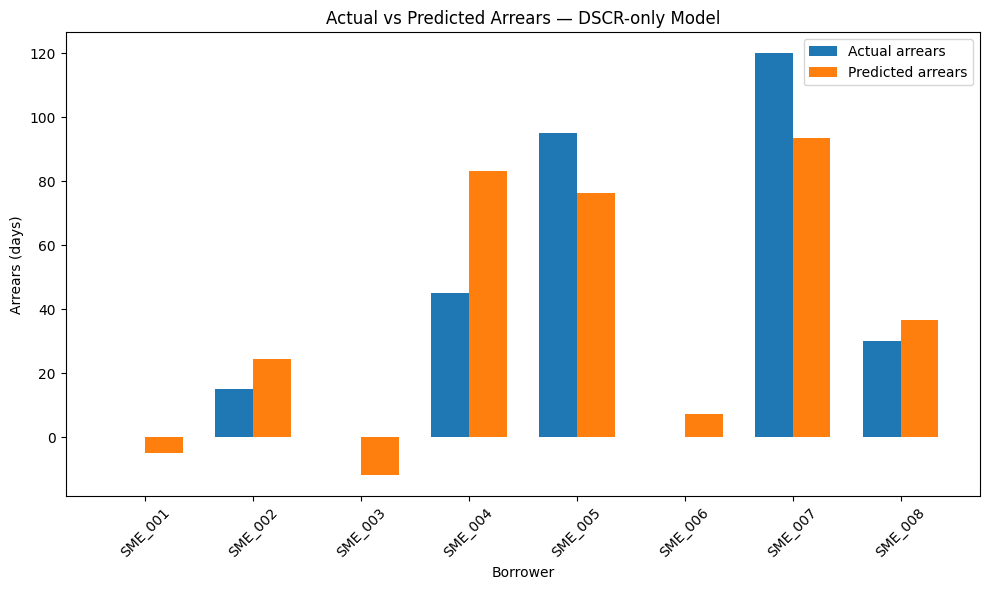

In [27]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

x = np.arange(len(df))
width = 0.35

plt.bar(
    x - width/2,
    df["Arrears_Days"],
    width,
    label="Actual arrears"
)

plt.bar(
    x + width/2,
    df["Predicted_Arrears"],
    width,
    label="Predicted arrears"
)

plt.xticks(x, df["Borrower"], rotation=45)
plt.xlabel("Borrower")
plt.ylabel("Arrears (days)")
plt.title("Actual vs Predicted Arrears — DSCR-only Model")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
# PROJECT 1: FINAL DATA AND MODEL AUDIT

print("DATASET CHECK")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())

print("\nPORTFOLIO CHECK")
print("Total exposure (₦m):", df["Exposure_m"].sum())
print("Average DSCR:", round(df["DSCR"].mean(), 3))

print("\nCORRELATION CHECK")
print("DSCR vs Arrears correlation:",
      round(df["DSCR"].corr(df["Arrears_Days"]), 4))

print("\nREGRESSION CHECK")
print("DSCR-only R-squared:", round(model1.rsquared, 3))
print("DSCR-only coefficient:",
      round(model1.params["DSCR"], 3))
print("DSCR-only p-value:",
      round(model1.pvalues["DSCR"], 4))

print("\nMODEL PERFORMANCE")
print("MAE:", round(mae, 2) if "mae" in globals() else "Check your MAE variable")
print("RMSE:", round(rmse, 2) if "rmse" in globals() else "Check your RMSE variable")

print("\nAUDIT COMPLETE")

DATASET CHECK
Rows: 8
Columns: 10
Missing values: 0

PORTFOLIO CHECK
Total exposure (₦m): 54
Average DSCR: 1.121

CORRELATION CHECK
DSCR vs Arrears correlation: -0.8994

REGRESSION CHECK
DSCR-only R-squared: 0.809
DSCR-only coefficient: -173.022
DSCR-only p-value: 0.0024

MODEL PERFORMANCE
MAE: 15.41
RMSE: 18.89

AUDIT COMPLETE



# Quantitative Analysis of an SME Credit Portfolio Using Python

**A Practical Statistics, Econometrics and Credit Risk Analysis Project**

**Prepared by:** Jesuferanmi David

**Tools:** Python, Google Colab, Pandas, NumPy, SciPy, Statsmodels and Matplotlib

**Dataset:** Synthetic SME credit portfolio — 8 borrowers

**Total Portfolio Exposure:** ₦54 million

**Project Category:** Mathematics, Statistics, Economics and Quantitative Analysis



## 1. Project Overview

This project applies statistical analysis and Python-based regression techniques to evaluate an illustrative portfolio of eight Small and Medium-sized Enterprise (SME) borrowers.

The analysis investigates the relationship between borrowers' Debt Service Coverage Ratio (DSCR) and loan arrears days.

Using Python, the project applies descriptive statistics, exploratory data analysis, correlation analysis, hypothesis testing, Ordinary Least Squares (OLS) regression, model diagnostics and prediction-error evaluation.

The objective is to demonstrate how quantitative methods can support the assessment of SME credit risk and inform evidence-based financial decisions.

**Important:** The dataset is synthetic and is used strictly for educational and analytical demonstration. It does not represent actual bank customer records.



## 2. Business Problem

Financial institutions that provide loans to Small and Medium-sized Enterprises (SMEs) face the challenge of identifying borrowers who may struggle to meet their repayment obligations.

A borrower's Debt Service Coverage Ratio (DSCR) provides an indication of their ability to meet debt obligations using available cash flow. However, a strong repayment-capacity indicator does not automatically guarantee timely loan repayment.

This project investigates whether DSCR can help explain variations in loan arrears days within a small illustrative SME portfolio.

The analysis also examines whether a regression model based on DSCR provides sufficiently reliable evidence for credit-risk assessment.

### Key Business Question

Can DSCR serve as a useful statistical indicator of SME loan arrears, and what limitations must be addressed before such a model could support actual lending decisions?



## 3. Project Objectives

The objectives of this analysis are to:

1. Examine the structure and characteristics of the SME credit portfolio.
2. Calculate borrower-level DSCR and assess repayment capacity.
3. Evaluate total credit exposure and sector concentration.
4. Investigate the relationship between DSCR and arrears days using correlation analysis.
5. Conduct statistical hypothesis testing to assess the significance of observed relationships.
6. Develop and interpret OLS regression models using Python.
7. Evaluate model assumptions through residual diagnostics and multicollinearity testing.
8. Compare alternative regression specifications.
9. Measure prediction errors using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).
10. Identify model limitations and recommend appropriate validation procedures before any production use.



## 4. Dataset Description

### 4.1 Data Source

The analysis uses a synthetic dataset created specifically for this quantitative demonstration.

It contains eight illustrative SME borrowers with financial and repayment-related information.

No actual customer records, confidential banking information or identifiable personal data are used.

### 4.2 Dataset Variables

| Variable | Description | Unit |
|---|---|---|
| Borrower | Unique borrower reference | Identifier |
| Sector | Borrower's business sector | Category |
| Exposure_m | Outstanding credit exposure | ₦ millions |
| Cashflow_m | Available borrower cash flow | ₦ millions |
| Debt_Service_m | Debt repayment obligation | ₦ millions |
| Arrears_Days | Number of days in arrears | Days |
| DSCR | Cash flow divided by debt service | Ratio |
| Risk_Status | Illustrative borrower risk classification | Category |

### 4.3 Portfolio Characteristics

- Number of borrowers: 8
- Total portfolio exposure: ₦54 million
- Number of sectors represented: 5
- Primary explanatory variable: DSCR
- Dependent variable: Arrears_Days

### 4.4 Key Analytical Assumption

DSCR is calculated as available cash flow divided by debt service.

A DSCR of 1.00 indicates that available cash flow equals the debt-service obligation. A value above 1.00 indicates cash flow exceeds the obligation, while a value below 1.00 indicates a shortfall.

The DSCR threshold of 1.20 used in the illustrative risk-screening exercise is an analytical assumption, not a universal regulatory standard.



## 5. Python Libraries and Tools

The analysis was conducted using Python in Google Colab.

The following libraries were used:

| Library | Purpose |
|---|---|
| Pandas | Data manipulation and analysis |
| NumPy | Numerical calculations |
| Matplotlib | Data visualization |
| SciPy | Correlation analysis and statistical testing |
| Statsmodels | OLS regression and statistical diagnostics |
| Seaborn | Statistical data visualization |
| Scikit-learn | Prediction-error evaluation |

### Analytical Environment

- Programming language: Python
- Development environment: Google Colab
- Data structure: Pandas DataFrame
- Statistical modelling: Statsmodels
- Visualization: Matplotlib and Seaborn



## 6. Python Setup and Data Preparation

### 6.1 Import Required Libraries

The following Python libraries support data manipulation, numerical computation, statistical analysis, regression modelling and visualization.


In [29]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All required libraries imported successfully.")


All required libraries imported successfully.



### 6.2 Create the SME Credit Dataset

A synthetic dataset containing eight SME borrowers was constructed for this analysis.

The dataset includes borrower sector, credit exposure, available cash flow, debt-service obligations and arrears days.


In [30]:
# Create the synthetic SME credit dataset

data = {
    "Borrower": ["SME_001", "SME_002", "SME_003", "SME_004",
                 "SME_005", "SME_006", "SME_007", "SME_008"],
    "Sector": ["Agriculture", "Retail", "Manufacturing", "Trading",
               "Agriculture", "Services", "Retail", "Manufacturing"],
    "Exposure_m": [8, 7, 6, 9, 5, 8, 6, 5],
    "Cashflow_m": [4.8, 3.6, 4.5, 3.0, 1.8, 5.2, 2.0, 3.4],
    "Debt_Service_m": [3.5, 3.0, 3.2, 3.5, 2.0, 4.0, 2.5, 3.0],
    "Arrears_Days": [0, 15, 0, 45, 95, 0, 120, 30]
}

df = pd.DataFrame(data)

# Calculate Debt Service Coverage Ratio
df["DSCR"] = (
    df["Cashflow_m"] / df["Debt_Service_m"]
).round(2)

# Display dataset
df

,Borrower,Sector,Exposure_m,Cashflow_m,Debt_Service_m,Arrears_Days,DSCR
0,SME_001,Agriculture,8,4.8,3.5,0,1.37
1,SME_002,Retail,7,3.6,3.0,15,1.20
2,SME_003,Manufacturing,6,4.5,3.2,0,1.41
3,SME_004,Trading,9,3.0,3.5,45,0.86
4,SME_005,Agriculture,5,1.8,2.0,95,0.90
5,SME_006,Services,8,5.2,4.0,0,1.30
6,SME_007,Retail,6,2.0,2.5,120,0.80
7,SME_008,Manufacturing,5,3.4,3.0,30,1.13



### 6.3 Borrower Risk Classification

Borrowers are assigned an illustrative risk status using two conditions:

- DSCR below 1.20.
- Arrears of 30 days or more.

A borrower meeting either condition is classified as **High Attention**. Otherwise, the borrower is classified as **Performing**.

This classification is a simplified analytical screening rule and is not an official bank credit-rating methodology.


In [31]:
# Classify borrowers based on DSCR and arrears

df["Risk_Status"] = np.where(
    (df["DSCR"] < 1.20) |
    (df["Arrears_Days"] >= 30),
    "High Attention",
    "Performing"
)

# Display borrower risk classification
df[["Borrower", "DSCR", "Arrears_Days", "Risk_Status"]]

,Borrower,DSCR,Arrears_Days,Risk_Status
0,SME_001,1.37,0,Performing
1,SME_002,1.20,15,Performing
2,SME_003,1.41,0,Performing
3,SME_004,0.86,45,High Attention
4,SME_005,0.90,95,High Attention
5,SME_006,1.30,0,Performing
6,SME_007,0.80,120,High Attention
7,SME_008,1.13,30,High Attention



### 6.4 Data Quality Checks

Data validation was performed to assess the structure, completeness and integrity of the dataset.

The checks include:

- Dataset dimensions.
- Missing values.
- Duplicate borrower records.
- Data types.
- Descriptive statistics.

These checks help identify potential data-quality issues before statistical modelling.


In [32]:
# Dataset validation

print("DATASET DIMENSIONS")
print(df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE BORROWERS")
print(df["Borrower"].duplicated().sum())

print("\nDATA TYPES")
print(df.dtypes)

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())

DATASET DIMENSIONS
(8, 8)

MISSING VALUES
Borrower          0
Sector            0
Exposure_m        0
Cashflow_m        0
Debt_Service_m    0
Arrears_Days      0
DSCR              0
Risk_Status       0
dtype: int64

DUPLICATE BORROWERS
0

DATA TYPES
Borrower           object
Sector             object
Exposure_m          int64
Cashflow_m        float64
Debt_Service_m    float64
Arrears_Days        int64
DSCR              float64
Risk_Status        object
dtype: object

DESCRIPTIVE STATISTICS


,Exposure_m,Cashflow_m,Debt_Service_m,Arrears_Days,DSCR
count,8.000000,8.000000,8.000000,8.000000,8.000000
mean,6.750000,3.537500,3.087500,38.125000,1.121250
std,1.488048,1.252355,0.624357,46.208959,0.240205
min,5.000000,1.800000,2.000000,0.000000,0.800000
25%,5.750000,2.750000,2.875000,0.000000,0.890000
50%,6.500000,3.500000,3.100000,22.500000,1.165000
75%,8.000000,4.575000,3.500000,57.500000,1.317500
max,9.000000,5.200000,4.000000,120.000000,1.410000


In [33]:
print("Dataset dimensions:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate borrowers:", df["Borrower"].duplicated().sum())

Dataset dimensions: (8, 8)
Missing values: 0
Duplicate borrowers: 0



## 7. Exploratory Data Analysis

### 7.1 Borrower-Level Credit Exposure

This analysis examines how the ₦54 million portfolio exposure is distributed across the eight SME borrowers.

The objective is to identify borrowers with relatively high credit exposure and understand the distribution of outstanding portfolio balances.


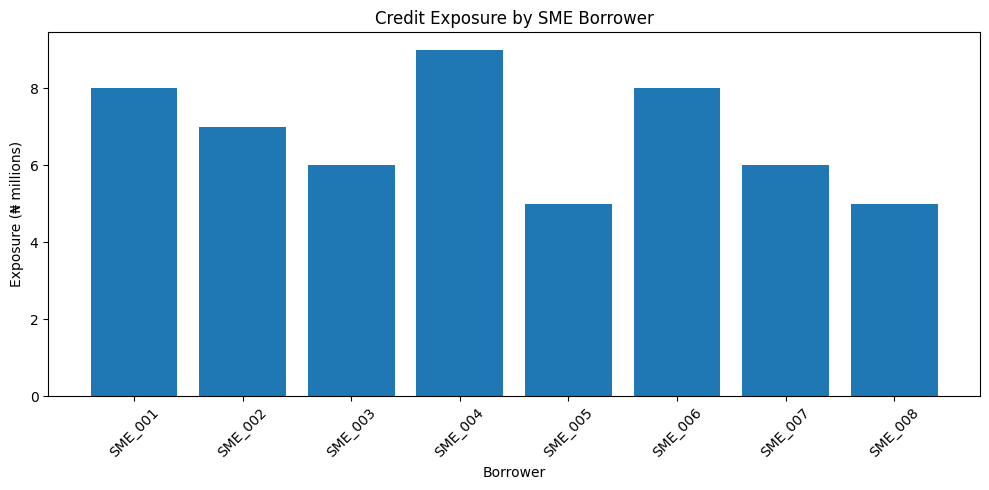

In [34]:
# Borrower-level credit exposure chart

plt.figure(figsize=(10, 5))

plt.bar(df["Borrower"], df["Exposure_m"])

plt.title("Credit Exposure by SME Borrower")
plt.xlabel("Borrower")
plt.ylabel("Exposure (₦ millions)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 7.2 Sector-Level Credit Exposure

This analysis examines the distribution of credit exposure across the five business sectors represented in the SME portfolio.

Sector concentration analysis helps identify whether a significant proportion of the institution's lending exposure is concentrated in particular economic activities.


CREDIT EXPOSURE BY SECTOR


,Exposure_m
Sector,
Agriculture,13
Retail,13
Manufacturing,11
Trading,9
Services,8


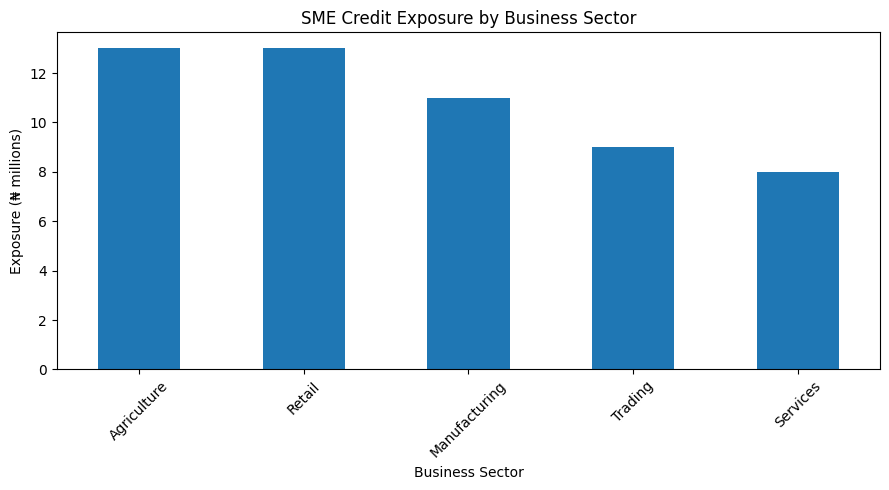

In [35]:
# Calculate total credit exposure by sector

sector_exposure = (
    df.groupby("Sector")["Exposure_m"]
    .sum()
    .sort_values(ascending=False)
)

print("CREDIT EXPOSURE BY SECTOR")
display(sector_exposure)

# Visualize sector exposure

plt.figure(figsize=(9, 5))

sector_exposure.plot(kind="bar")

plt.title("SME Credit Exposure by Business Sector")
plt.xlabel("Business Sector")
plt.ylabel("Exposure (₦ millions)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### 7.3 Borrower Repayment Capacity Analysis

The Debt Service Coverage Ratio (DSCR) measures the ability of a borrower to meet debt-service obligations using available cash flow.

A DSCR above 1.00 indicates that available cash flow exceeds debt-service obligations, while a DSCR below 1.00 indicates a cash-flow shortfall.

This analysis compares DSCR across borrowers and uses an illustrative threshold of 1.20 to identify borrowers requiring additional attention.


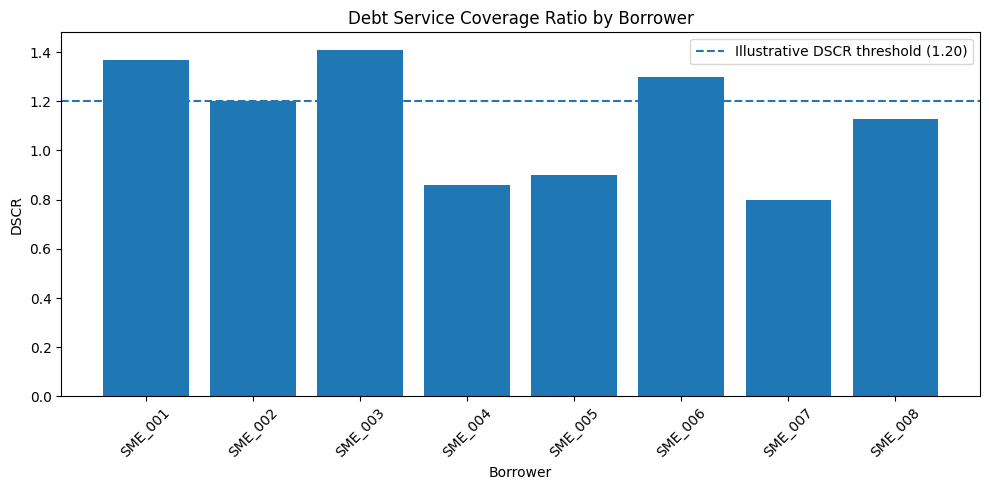

In [36]:
# Compare DSCR across borrowers

plt.figure(figsize=(10, 5))

plt.bar(df["Borrower"], df["DSCR"])

# Illustrative DSCR threshold
plt.axhline(
    y=1.20,
    linestyle="--",
    label="Illustrative DSCR threshold (1.20)"
)

plt.title("Debt Service Coverage Ratio by Borrower")
plt.xlabel("Borrower")
plt.ylabel("DSCR")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()


### 7.4 Borrower Arrears Analysis

This analysis examines the distribution of loan arrears across the eight SME borrowers.

Arrears days provide an indication of repayment delays and help identify borrowers experiencing repayment difficulties.

The analysis compares borrower-level arrears to identify the extent and distribution of repayment delays within the portfolio.


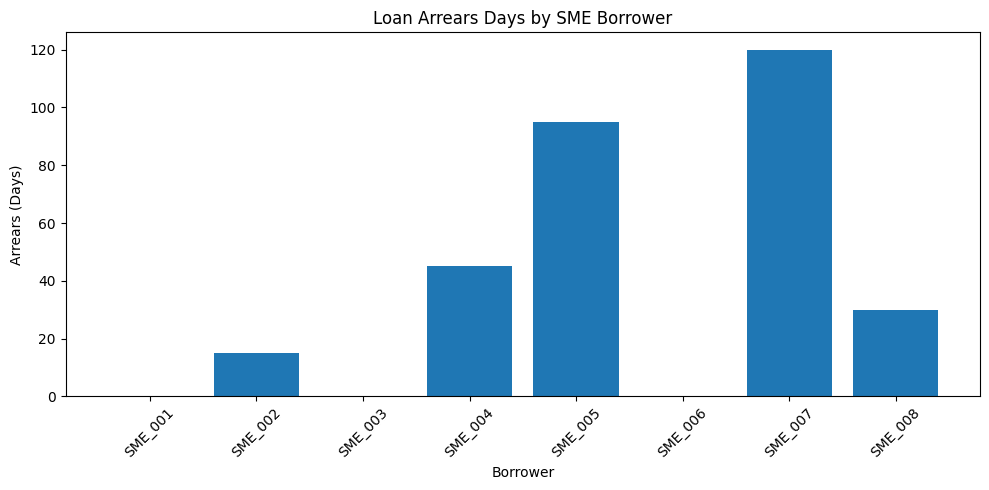

In [37]:
# Visualize arrears days by borrower

plt.figure(figsize=(10, 5))

plt.bar(df["Borrower"], df["Arrears_Days"])

plt.title("Loan Arrears Days by SME Borrower")
plt.xlabel("Borrower")
plt.ylabel("Arrears (Days)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### 7.5 Portfolio Exposure in 90+ Day Arrears

This analysis calculates the proportion of total portfolio exposure associated with borrowers whose arrears have reached 90 days or more.

The measure provides an illustrative indicator of severe repayment delinquency and portfolio credit-risk concentration.

It is a screening proxy and should not automatically be interpreted as the bank's official regulatory Non-Performing Loan (NPL) ratio or IFRS 9 Stage 3 exposure.


In [38]:
# Calculate exposure associated with 90+ day arrears

total_exposure = df["Exposure_m"].sum()

exposure_90_plus = df.loc[
    df["Arrears_Days"] >= 90,
    "Exposure_m"
].sum()

ratio_90_plus = (
    exposure_90_plus / total_exposure
) * 100

print("Total Portfolio Exposure: ₦", total_exposure, "million")
print("Exposure in 90+ Day Arrears: ₦", exposure_90_plus, "million")
print("90+ Day Arrears Exposure Ratio:", round(ratio_90_plus, 2), "%")

Total Portfolio Exposure: ₦ 54 million
Exposure in 90+ Day Arrears: ₦ 11 million
90+ Day Arrears Exposure Ratio: 20.37 %


### 7.6 Portfolio Risk Classification Summary

This section summarizes the distribution of borrowers and credit exposure across the two risk categories: Performing and High Attention.

The classification uses the illustrative screening rule established earlier:
- High Attention: DSCR below 1.20 OR arrears of 30 days or more.
- Performing: DSCR of 1.20 or higher AND arrears below 30 days.

This is an analytical screening rule, not an official regulatory loan classification.

PORTFOLIO RISK CLASSIFICATION SUMMARY


,Borrower_Count,Total_Exposure_m,Exposure_Percentage
Risk_Status,,,
High Attention,4,25,46.3
Performing,4,29,53.7


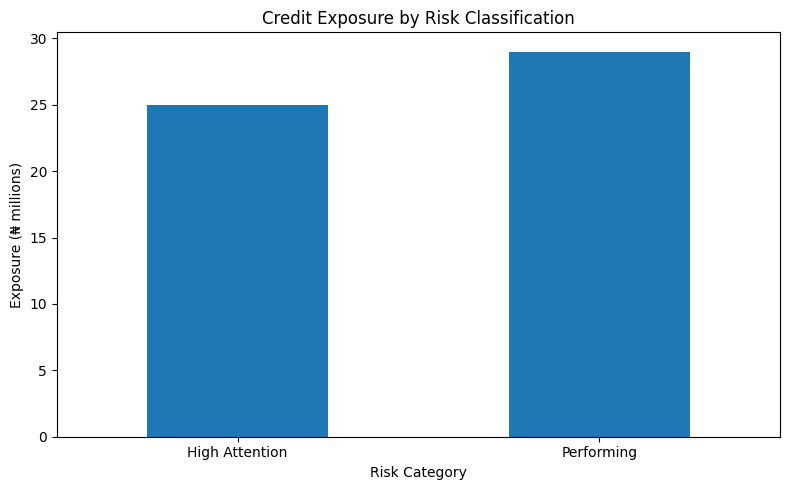

In [39]:
risk_summary = df.groupby("Risk_Status").agg(
    Borrower_Count=("Borrower", "count"),
    Total_Exposure_m=("Exposure_m", "sum")
)

risk_summary["Exposure_Percentage"] = (
    risk_summary["Total_Exposure_m"] /
    df["Exposure_m"].sum()
) * 100

print("PORTFOLIO RISK CLASSIFICATION SUMMARY")
display(risk_summary.round(2))

plt.figure(figsize=(8, 5))
risk_summary["Total_Exposure_m"].plot(kind="bar")

plt.title("Credit Exposure by Risk Classification")
plt.xlabel("Risk Category")
plt.ylabel("Exposure (₦ millions)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.7 DSCR Distribution Analysis

This section examines the distribution of DSCR values across the SME portfolio.

A histogram and a density curve will help identify the spread, concentration, and potential skewness of borrowers' repayment capacity.

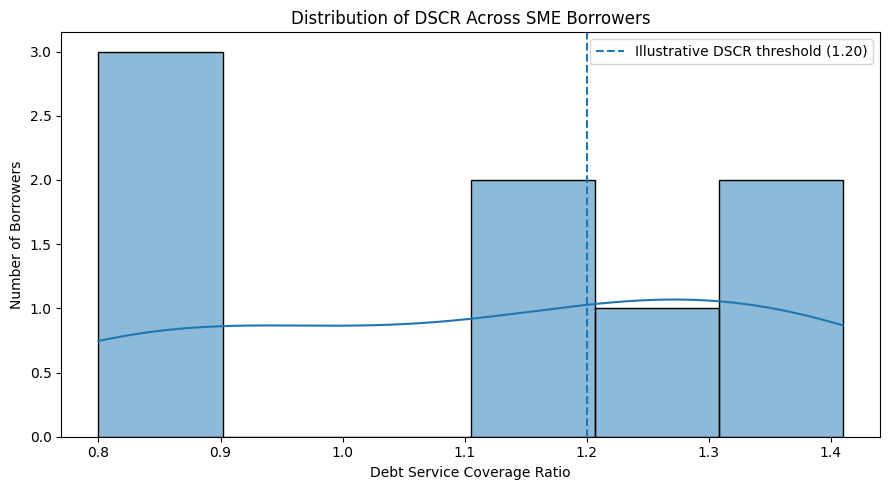

In [40]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="DSCR",
    bins=6,
    kde=True
)

plt.axvline(
    x=1.20,
    linestyle="--",
    label="Illustrative DSCR threshold (1.20)"
)

plt.title("Distribution of DSCR Across SME Borrowers")
plt.xlabel("Debt Service Coverage Ratio")
plt.ylabel("Number of Borrowers")
plt.legend()
plt.tight_layout()
plt.show()

### 7.8 Descriptive Statistics by Risk Category

This section compares average exposure, cash flow, debt service, DSCR, and arrears days across the two risk categories.

The comparison helps identify the characteristics that distinguish borrowers requiring closer credit monitoring.

In [41]:
risk_comparison = df.groupby("Risk_Status").agg(
    Average_Exposure=("Exposure_m", "mean"),
    Average_Cashflow=("Cashflow_m", "mean"),
    Average_Debt_Service=("Debt_Service_m", "mean"),
    Average_DSCR=("DSCR", "mean"),
    Average_Arrears=("Arrears_Days", "mean")
)

print("AVERAGE FINANCIAL CHARACTERISTICS BY RISK CATEGORY")
display(risk_comparison.round(2))

AVERAGE FINANCIAL CHARACTERISTICS BY RISK CATEGORY


,Average_Exposure,Average_Cashflow,Average_Debt_Service,Average_DSCR,Average_Arrears
Risk_Status,,,,,
High Attention,6.25,2.55,2.75,0.92,72.50
Performing,7.25,4.53,3.42,1.32,3.75


### 7.8.1 Interpretation and Business Implications

The descriptive comparison indicates that High Attention borrowers have weaker average cash flow, lower DSCR, and substantially higher arrears than Performing borrowers.

These findings suggest that cash-flow monitoring, repayment-capacity assessment, and early-warning indicators are important components of SME credit-risk management.

However, the observed differences are descriptive and do not establish causality. Furthermore, because DSCR and arrears contribute to the risk classification rule, their differences across categories should be interpreted with this methodological limitation in mind.

### 7.9 Correlation Analysis

Correlation analysis examines the strength and direction of the linear relationship between DSCR and arrears days.

The Pearson correlation coefficient ranges from -1 to +1:
- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear correlation.

This analysis will help determine whether borrowers with stronger debt-service coverage tend to have fewer arrears days.

In [42]:
correlation, p_value = stats.pearsonr(
    df["DSCR"],
    df["Arrears_Days"]
)

print("PEARSON CORRELATION ANALYSIS")
print("Correlation coefficient:", round(correlation, 4))
print("P-value:", round(p_value, 4))

PEARSON CORRELATION ANALYSIS
Correlation coefficient: -0.8994
P-value: 0.0024


### 7.9.1 Interpretation of Correlation Results

The Pearson correlation coefficient between DSCR and arrears days is -0.8994, indicating a very strong negative linear association.

The p-value of 0.0024 is below the 5% significance level. Therefore, the null hypothesis of zero population correlation is rejected under the assumptions of the Pearson correlation test.

The result suggests that borrowers with stronger debt-service coverage tend to experience fewer arrears days within this synthetic dataset.

However, correlation does not establish causation. The small sample size of eight borrowers limits statistical reliability and generalizability. The findings should therefore be treated as illustrative rather than conclusive evidence about real-world SME credit portfolios.

### 7.10 Scatterplot of DSCR and Arrears Days

A scatterplot is used to visualize the relationship between DSCR and arrears days.

The fitted regression line illustrates the direction of the linear association between the two variables.

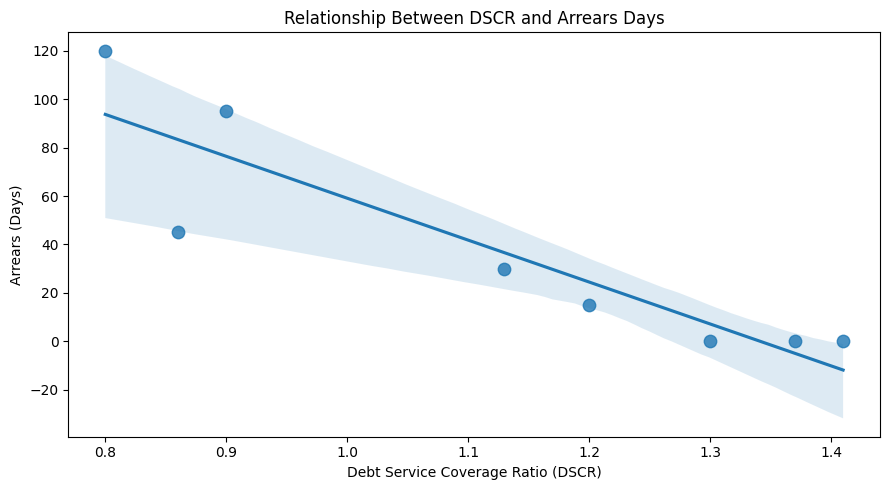

In [43]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="DSCR",
    y="Arrears_Days",
    ci=95,
    scatter_kws={"s": 80}
)

plt.title("Relationship Between DSCR and Arrears Days")
plt.xlabel("Debt Service Coverage Ratio (DSCR)")
plt.ylabel("Arrears (Days)")
plt.tight_layout()
plt.show()

### 7.10.1 Interpretation of Scatterplot

The scatterplot displays a clear downward-sloping linear trend between DSCR and arrears days.

Borrowers with higher DSCR values generally have fewer arrears days, while borrowers with lower DSCR values tend to have more arrears days.

The visual pattern supports the Pearson correlation coefficient of -0.8994, indicating a very strong negative linear association.

However, the small sample size limits generalizability, and the relationship should not be interpreted as causal.

## 8. Multiple Linear Regression Analysis

Multiple linear regression is used to examine the relationship between a dependent variable and two or more independent variables.

In this project:

- Dependent variable (Y): Arrears_Days
- Independent variable (X1): DSCR
- Independent variable (X2): Cashflow_m

The objective is to investigate whether DSCR and borrower cash flow jointly explain variations in arrears days.

The regression analysis will examine:
- Model fit using R-squared and Adjusted R-squared.
- Overall model significance using the F-statistic.
- Individual predictor significance using t-statistics and p-values.
- Regression coefficients and their confidence intervals.
- Potential multicollinearity and other model assumptions.

This analysis is exploratory and does not establish causal relationships or demonstrate out-of-sample predictive performance.

In [44]:
# Define independent variables
X = df[["DSCR", "Cashflow_m"]]

# Define dependent variable
y = df["Arrears_Days"]

# Add the intercept
X = sm.add_constant(X)

print("INDEPENDENT VARIABLES")
display(X)

print("DEPENDENT VARIABLE")
display(y)

INDEPENDENT VARIABLES


,const,DSCR,Cashflow_m
0,1.0,1.37,4.8
1,1.0,1.20,3.6
2,1.0,1.41,4.5
3,1.0,0.86,3.0
4,1.0,0.90,1.8
5,1.0,1.30,5.2
6,1.0,0.80,2.0
7,1.0,1.13,3.4


DEPENDENT VARIABLE


,Arrears_Days
0,0
1,15
2,0
3,45
4,95
5,0
6,120
7,30


In [45]:
# Fit the multiple linear regression model
model = sm.OLS(y, X).fit()

# Display the regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Arrears_Days   R-squared:                       0.883
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     18.84
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00470
Time:                        10:40:38   Log-Likelihood:                -32.906
No. Observations:                   8   AIC:                             71.81
Df Residuals:                       5   BIC:                             72.05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        189.8023     41.254      4.601      0.0

### 8.4 Multicollinearity Assessment Using VIF

Variance Inflation Factor (VIF) is used to assess multicollinearity among independent variables.

High multicollinearity can inflate coefficient standard errors, reduce the precision of individual estimates, and make it difficult to isolate the contribution of each predictor.

This analysis evaluates whether DSCR and Cashflow_m contain overlapping explanatory information.

In [46]:
# Calculate VIF for each independent variable
vif_data = pd.DataFrame()

vif_data["Variable"] = X.columns

vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print("VARIANCE INFLATION FACTOR (VIF)")
display(vif_data.round(3))

VARIANCE INFLATION FACTOR (VIF)


,Variable,VIF
0,const,1.000
1,DSCR,5.686
2,Cashflow_m,5.686


### 8.4.1 Interpretation of Multicollinearity

The Variance Inflation Factor (VIF) results show that both DSCR and Cashflow_m have VIF values of 5.686. These values indicate potentially elevated multicollinearity between the explanatory variables.

This overlap is understandable because DSCR is calculated using cash flow divided by debt service. Consequently, cash flow is already represented in the DSCR measure.

The multicollinearity may make it difficult to isolate the individual contribution of each predictor, potentially increasing standard errors and reducing the statistical significance of individual regression coefficients.

However, VIF values alone do not establish that the model is invalid. The results should be considered alongside the regression output, residual diagnostics, sample size, and model comparison.

Given the small sample of eight synthetic borrowers, the regression findings should be treated as exploratory rather than suitable for operational credit decisions.

### 8.5 Interpretation of Multicollinearity

The Variance Inflation Factor (VIF) results show that DSCR and Cashflow_m both have VIF values of approximately 5.686.

These values suggest potentially elevated multicollinearity between the independent variables. Although they exceed the commonly used threshold of 5, they remain below the threshold of 10 often associated with more serious multicollinearity.

This finding provides a plausible explanation for the relatively large standard errors and individually insignificant coefficients observed in the multiple regression model.

The relationship is also understandable because DSCR is calculated using cash flow divided by debt service, meaning the two predictors share mathematical information.

However, VIF values alone do not establish that multicollinearity is severe. The findings should be considered alongside the model's small sample size, coefficient uncertainty, and conceptual justification for including both predictors.

### 8.6 Residual Diagnostics

Residual diagnostics help assess whether the regression model's assumptions are reasonably satisfied.

The residual-versus-fitted plot is used to examine whether residuals are randomly distributed around zero or whether systematic patterns exist.

A random scatter around zero is generally desirable, while visible curves, trends, or funnel shapes may indicate non-linearity or non-constant error variance.

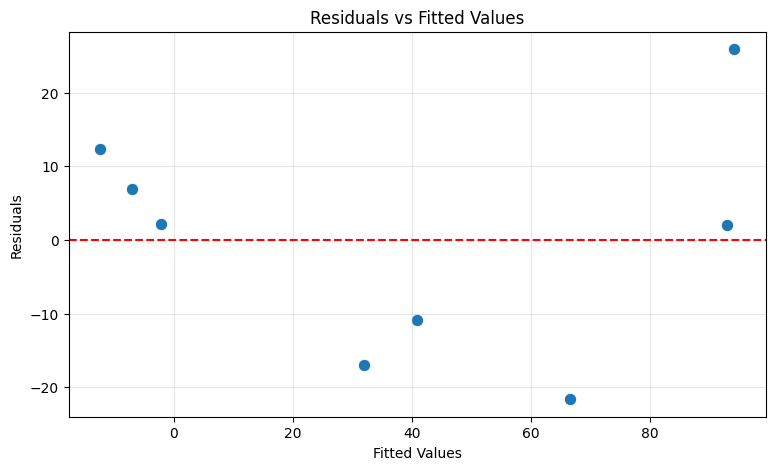

In [47]:
# Calculate fitted values and residuals
fitted_values = model.fittedvalues
residuals = model.resid

# Plot residuals against fitted values
plt.figure(figsize=(9, 5))
sns.scatterplot(x=fitted_values, y=residuals, s=80)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.grid(True, alpha=0.3)
plt.show()

### 8.7 Interpretation of the Residual-versus-Fitted Plot

The residual-versus-fitted plot displays a U-shaped or curved pattern rather than a completely random distribution around zero.

This may indicate non-linearity, suggesting that the linear regression model does not fully capture the relationship between the predictors and arrears days.

The observed pattern raises the possibility of model misspecification or omitted nonlinear effects.

However, the dataset contains only eight synthetic observations. Therefore, this finding should be treated as a diagnostic warning rather than conclusive evidence of non-linearity.

### 8.8 Normality Assessment Using a Q-Q Plot

A Quantile-Quantile (Q-Q) plot is used to assess whether regression residuals approximately follow a normal distribution.

If the plotted points fall close to the diagonal reference line, this provides visual support for approximate normality.

Substantial deviations, particularly at the tails, may suggest departures from normality.

Because this project contains only eight observations, conclusions from the Q-Q plot must be interpreted cautiously.

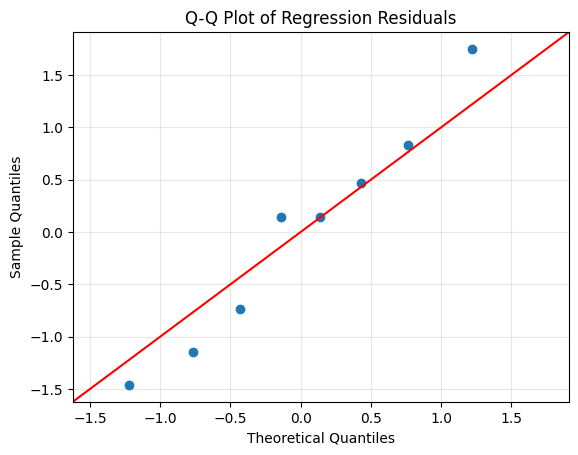

In [48]:
# Generate Q-Q plot of regression residuals
sm.qqplot(residuals, line="45", fit=True)

plt.title("Q-Q Plot of Regression Residuals")
plt.grid(True, alpha=0.3)
plt.show()

### 8.9 Interpretation of the Q-Q Plot

The Q-Q plot shows that most residual points follow the diagonal reference line, although slight deviations are visible at the tails.

This provides some visual support for approximate normality of the regression residuals.

However, the small sample size of eight observations limits the reliability of this assessment. Therefore, normality cannot be conclusively established from the Q-Q plot alone.

The result should be interpreted alongside other regression diagnostics and the limitations of the dataset.

### 8.10 Breusch–Pagan Test for Heteroscedasticity

The Breusch–Pagan test examines whether the variance of regression residuals is constant across observations.

Hypotheses:

- H0: The residuals have constant variance (homoscedasticity).
- H1: The residuals have non-constant variance (heteroscedasticity).

At a 5% significance level:

- If p-value < 0.05, reject H0.
- If p-value >= 0.05, fail to reject H0.

The test results must be interpreted cautiously because this dataset contains only eight observations.

In [49]:
# Perform Breusch-Pagan test
bp_test = het_breuschpagan(residuals, X)

labels = ["LM Statistic", "LM-Test p-value",
          "F-Statistic", "F-Test p-value"]

print("BREUSCH-PAGAN TEST RESULTS")

for label, value in zip(labels, bp_test):
    print(f"{label}: {value:.4f}")

BREUSCH-PAGAN TEST RESULTS
LM Statistic: 4.7743
LM-Test p-value: 0.0919
F-Statistic: 3.7002
F-Test p-value: 0.1032


### 8.11 Interpretation of the Breusch–Pagan Test

The Breusch–Pagan test produced an LM statistic of 4.7743 with a p-value of 0.0919. The F-statistic was 3.7002 with a corresponding p-value of 0.1032.

At the 5% significance level, both p-values exceed 0.05. Therefore, we fail to reject the null hypothesis of constant residual variance.

This indicates insufficient statistical evidence of heteroscedasticity in the regression model.

However, failure to reject the null hypothesis does not prove that heteroscedasticity is absent. Given the very small sample size of eight observations, the test may have limited power to detect non-constant variance.

### 8.12 Overall Regression Diagnostics Summary

The regression diagnostics reveal several important findings:

1. **Linearity:** The residual-versus-fitted plot displays a curved pattern, suggesting possible non-linearity or model misspecification.

2. **Normality:** The Q-Q plot shows that most residuals follow the diagonal reference line, with slight deviations at the tails. Approximate normality is plausible but cannot be established conclusively.

3. **Homoscedasticity:** The Breusch–Pagan test produces p-values greater than 0.05. Therefore, there is insufficient evidence to reject the assumption of constant residual variance.

4. **Multicollinearity:** Both DSCR and Cashflow_m have VIF values of approximately 5.686, suggesting potentially elevated multicollinearity.

Overall, the diagnostic results indicate that the regression model has limitations, particularly possible non-linearity and predictor overlap. These findings, together with the small sample size of eight observations, mean that the model should be treated as exploratory rather than suitable for operational credit-risk decisions.

### 8.12 Overall Regression Diagnostics Summary

The regression diagnostics reveal several important findings:

1. **Linearity:** The residual-versus-fitted plot displays a curved pattern, suggesting possible non-linearity or model misspecification.

2. **Normality:** The Q-Q plot shows that most residuals follow the diagonal reference line, with slight deviations at the tails. Approximate normality is plausible but cannot be established conclusively.

3. **Homoscedasticity:** The Breusch–Pagan test produces p-values greater than 0.05. Therefore, there is insufficient evidence to reject the assumption of constant residual variance.

4. **Multicollinearity:** Both DSCR and Cashflow_m have VIF values of approximately 5.686, suggesting potentially elevated multicollinearity.

Overall, the diagnostic results indicate that the regression model has limitations, particularly possible non-linearity and predictor overlap. These findings, together with the small sample size of eight observations, mean that the model should be treated as exploratory rather than suitable for operational credit-risk decisions.

In [50]:
# Compare regression model performance

comparison = pd.DataFrame({
    "Model": ["DSCR Only", "DSCR + Cashflow"],
    "R-squared": [model1.rsquared, model.rsquared],
    "Adjusted R-squared": [
        model1.rsquared_adj,
        model.rsquared_adj
    ],
    "AIC": [model1.aic, model.aic],
    "BIC": [model1.bic, model.bic]
})

display(comparison.round(4))

,Model,R-squared,Adjusted R-squared,AIC,BIC
0,DSCR Only,0.8089,0.7771,73.7247,73.8835
1,DSCR + Cashflow,0.8828,0.8360,71.8120,72.0503


### 9.2 Nested F-Test for Model Comparison

A nested F-test evaluates whether adding an independent variable significantly improves a restricted regression model.

For this analysis:

- Restricted model: DSCR only.
- Full model: DSCR and Cashflow_m.

Hypotheses:

- H0: Adding Cashflow_m does not significantly improve the model.
- H1: Adding Cashflow_m significantly improves the model.

At a 5% significance level, reject H0 if the p-value is below 0.05.

In [51]:
# Compare the restricted and full regression models
f_stat, p_value, df_diff = model.compare_f_test(model1)

print("NESTED F-TEST RESULTS")
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of freedom difference: {df_diff:.0f}")

NESTED F-TEST RESULTS
F-statistic: 3.1541
p-value: 0.1359
Degrees of freedom difference: 1


### 9.3 Interpretation of the Nested F-Test

The nested F-test produced an F-statistic of 3.1541 and a p-value of 0.1359.

Since the p-value exceeds the 5% significance threshold, we fail to reject the null hypothesis.

This indicates that adding Cashflow_m does not provide a statistically significant improvement over the DSCR-only regression model.

Although the multiple regression model has higher R-squared and adjusted R-squared values and lower AIC and BIC values, the nested F-test does not establish a statistically significant improvement.

Given the small sample size and potential multicollinearity, the DSCR-only model is provisionally preferred for its simplicity and parsimony. This preference does not establish superior predictive performance on new data.

### 9.4 DSCR-Only Regression Model

The DSCR-only regression model uses Debt Service Coverage Ratio (DSCR) as its sole independent variable to estimate arrears days.

The model is:

Arrears_Days = β₀ + β₁(DSCR) + ε

This specification is examined because the nested F-test did not show a statistically significant improvement from adding Cashflow_m.

The analysis will evaluate model fit, coefficient significance, prediction errors, and the practical limitations of using DSCR as a standalone predictor.

In [52]:
# Fit the DSCR-only regression model

X1 = sm.add_constant(df[["DSCR"]])
y = df["Arrears_Days"]

model1 = sm.OLS(y, X1).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:           Arrears_Days   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.777
Method:                 Least Squares   F-statistic:                     25.40
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00236
Time:                        10:40:39   Log-Likelihood:                -34.862
No. Observations:                   8   AIC:                             73.72
Df Residuals:                       6   BIC:                             73.88
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        232.1254     39.257      5.913      0.0

### 9.5 Interpretation of the DSCR-Only Regression Model

The DSCR-only regression model produced an R-squared of 0.809 and an adjusted R-squared of 0.777, indicating that approximately 80.9% of the variation in arrears days is explained by DSCR within this synthetic sample.

The overall regression model is statistically significant, with an F-statistic of 25.40 and a p-value of 0.00236.

The DSCR coefficient is -173.0216, with a p-value of 0.002. This indicates a statistically significant negative association between DSCR and arrears days in the sample.

Holding the fitted linear relationship constant, a 0.1 increase in DSCR corresponds to approximately 17.3 fewer predicted arrears days.

The 95% confidence interval for the DSCR coefficient ranges from -257.023 to -89.020, remaining entirely below zero.

Despite these results, the model is exploratory. It uses only eight synthetic observations, has not undergone independent validation, and does not establish causality or reliable predictive performance for new borrowers.

### 9.6 Prediction Error Evaluation

Prediction errors measure the difference between actual arrears days and values estimated by the regression model.

Two evaluation metrics are used:

1. Mean Absolute Error (MAE): Measures the average absolute prediction error in days.
2. Root Mean Squared Error (RMSE): Measures prediction error while giving greater weight to larger errors.

The model's errors will also be compared with a simple baseline that predicts the mean arrears value for every borrower.

These are in-sample evaluation metrics and should not be interpreted as independent evidence of predictive performance.

In [53]:
# Generate predictions from the DSCR-only model
predictions = model1.predict(X1)

# Calculate model prediction errors
mae = mean_absolute_error(y, predictions)
rmse = np.sqrt(mean_squared_error(y, predictions))

# Calculate baseline predictions using mean arrears
baseline_predictions = np.repeat(y.mean(), len(y))

baseline_mae = mean_absolute_error(y, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y, baseline_predictions)
)

print("DSCR-ONLY MODEL PERFORMANCE")
print(f"Model MAE: {mae:.2f} days")
print(f"Model RMSE: {rmse:.2f} days")

print("\nBASELINE PERFORMANCE")
print(f"Baseline MAE: {baseline_mae:.2f} days")
print(f"Baseline RMSE: {baseline_rmse:.2f} days")

DSCR-ONLY MODEL PERFORMANCE
Model MAE: 15.41 days
Model RMSE: 18.89 days

BASELINE PERFORMANCE
Baseline MAE: 36.41 days
Baseline RMSE: 43.22 days


### 9.7 Interpretation of Prediction Error Metrics

The DSCR-only regression model produced an MAE of 15.41 days and an RMSE of 18.89 days.

The baseline model, which predicts the mean arrears value for every borrower, produced an MAE of 36.41 days and an RMSE of 43.22 days.

The DSCR-only model therefore achieved approximately 57.7% lower MAE than the baseline on the same dataset.

This indicates better in-sample estimation than the simple mean-based baseline.

However, these results do not demonstrate reliable predictive performance on unseen borrowers because the model was evaluated using the same eight observations used for estimation.

Independent validation using a larger dataset is necessary before considering operational deployment.

### 9.8 Actual versus Predicted Arrears

This section compares actual arrears days with the values predicted by the DSCR-only regression model for each borrower.

The comparison helps identify individual prediction errors and assess whether the model systematically overestimates or underestimates arrears.

Negative predicted arrears values will also be examined because arrears days cannot be negative in practice.

In [54]:
# Create actual-versus-predicted comparison
prediction_comparison = pd.DataFrame({
    "Borrower": df["Borrower"],
    "Actual_Arrears": y,
    "Predicted_Arrears": predictions.round(2)
})

prediction_comparison["Residual"] = (
    prediction_comparison["Actual_Arrears"]
    - prediction_comparison["Predicted_Arrears"]
).round(2)

display(prediction_comparison)

,Borrower,Actual_Arrears,Predicted_Arrears,Residual
0,SME_001,0,-4.91,4.91
1,SME_002,15,24.50,-9.50
2,SME_003,0,-11.83,11.83
3,SME_004,45,83.33,-38.33
4,SME_005,95,76.41,18.59
5,SME_006,0,7.20,-7.20
6,SME_007,120,93.71,26.29
7,SME_008,30,36.61,-6.61


### 9.9 Interpretation of Actual versus Predicted Arrears

The comparison shows that the DSCR-only model captures a general inverse relationship between DSCR and arrears days, but prediction errors vary across borrowers.

The model overestimates arrears for some borrowers and underestimates them for others. SME_004 has the largest absolute prediction error, with an overestimation of 38.33 days. SME_007 is underestimated by 26.29 days.

The model also produces negative predicted arrears values for SME_001 and SME_003. Although ordinary linear regression permits negative predictions, these values are not operationally meaningful because arrears days cannot be negative.

These findings highlight the limitations of an unconstrained linear regression model for this outcome. Alternative modelling approaches that account for the non-negative and potentially skewed nature of arrears data may be worth investigating.

The results remain exploratory because the model uses only eight synthetic observations and has not been independently validated.

### 9.10 Visual Comparison of Actual and Predicted Arrears

A scatter plot is used to compare actual arrears days with the values predicted by the DSCR-only regression model.

The 45-degree reference line represents perfect prediction. Points close to this line indicate smaller prediction errors, while points farther away indicate larger errors.

This visualization helps identify the extent of prediction differences across borrowers.

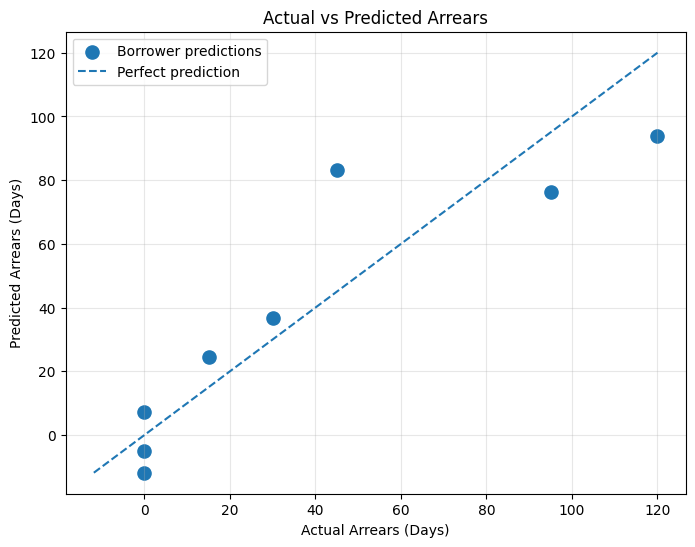

In [55]:
# Plot actual versus predicted arrears

plt.figure(figsize=(8, 6))

plt.scatter(
    y,
    predictions,
    s=90,
    label="Borrower predictions"
)

# Reference line for perfect predictions
min_value = min(y.min(), predictions.min())
max_value = max(y.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Arrears (Days)")
plt.ylabel("Predicted Arrears (Days)")
plt.title("Actual vs Predicted Arrears")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 9.11 Interpretation of Actual versus Predicted Arrears Plot

The scatter plot shows that some borrower predictions are relatively close to the 45-degree perfect-prediction reference line, while others are substantially distant.

This indicates variation in the model's prediction accuracy across borrowers.

The visual findings are consistent with the prediction error table, particularly the larger errors observed for SME_004 and SME_007.

Overall, the model captures some of the variation in arrears days but does not provide consistently accurate borrower-level predictions.

The findings reinforce the need for a larger dataset, alternative model specifications, and independent validation before operational use.

### 9.12 Model Limitations and Alternative Approaches

The DSCR-only regression model provides useful exploratory evidence of the relationship between repayment capacity and arrears days. However, several limitations must be considered.

**1. Small sample size**

The model uses only eight synthetic borrowers. This is insufficient for reliable generalization or independent model validation.

**2. Negative predictions**

The linear regression model produces negative arrears predictions for some borrowers, although arrears days cannot be negative in practice.

**3. Possible non-linearity**

The residual-versus-fitted plot displays a curved pattern, suggesting that a straight-line relationship may not adequately capture the underlying data.

**4. Limited explanatory variables**

The model uses DSCR alone and does not account for other potentially relevant factors such as borrower sector, leverage, collateral, repayment history, or economic conditions.

**5. No independent validation**

The prediction errors were evaluated on the same observations used to estimate the model. Therefore, the reported performance may be optimistic.

**Potential alternative approaches**

- Poisson regression: May be appropriate if arrears days are treated as count data and its distributional assumptions are reasonable.
- Negative Binomial regression: May be more appropriate if count data exhibit overdispersion.
- Two-part or zero-inflated models: May be worth investigating if the data contain many zero-arrears observations.
- Nonlinear regression or other flexible models: May help capture nonlinear relationships, provided sufficient data are available.

The choice of an alternative model should depend on the outcome distribution, research objective, sample size, and model assumptions.

**Overall conclusion:** The DSCR-only OLS model is useful for demonstrating quantitative analysis and exploratory modelling, but it is not suitable for operational credit-risk decisions in its current form.

# 10. Executive Summary and Key Findings

### 10.1 Executive Summary

This project applies statistical analysis and regression modelling to a synthetic SME credit portfolio containing eight borrowers with a combined credit exposure of ₦54 million.

The analysis was conducted using Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Statsmodels, and Scikit-learn.

The primary objective was to examine the relationship between Debt Service Coverage Ratio (DSCR) and loan arrears, identify portfolio risk patterns, and evaluate the usefulness and limitations of linear regression for estimating arrears days.

The analysis produced the following findings:

1. **Portfolio exposure:** Total credit exposure was ₦54 million. Agriculture and Retail accounted for the largest combined sector exposure of ₦26 million, representing approximately 48.15% of the portfolio.

2. **Arrears concentration:** Two borrowers had arrears of at least 90 days, representing ₦11 million or approximately 20.37% of total portfolio exposure.

3. **Repayment capacity:** The average DSCR was approximately 1.12. The Pearson correlation between DSCR and arrears days was -0.8994, indicating a strong negative association within the synthetic sample.

4. **Multiple regression:** The two-predictor regression model achieved an R-squared of 0.883. However, neither DSCR nor Cashflow_m was individually statistically significant at the 5% level.

5. **Multicollinearity:** Both predictors recorded VIF values of approximately 5.686, indicating potentially elevated multicollinearity.

6. **Model comparison:** The nested F-test produced a p-value of 0.1359, indicating that adding Cashflow_m did not significantly improve the DSCR-only model at the 5% significance level.

7. **DSCR-only regression:** The simpler model achieved an R-squared of 0.809, with a statistically significant negative DSCR coefficient (p = 0.002).

8. **Prediction evaluation:** The DSCR-only model achieved an in-sample MAE of 15.41 days, compared with 36.41 days for the mean-based baseline. However, negative predicted arrears values and borrower-level prediction errors revealed important model limitations.

Overall, the project demonstrates the application of descriptive statistics, correlation analysis, regression modelling, diagnostic testing, and model evaluation to a quantitative credit-risk problem.

Because the dataset contains only eight synthetic observations and has not undergone independent validation, the findings are educational and exploratory. They should not be interpreted as evidence of actual bank portfolio performance or used to make real lending decisions.

### 10.2 Research Methodology

**Research Design**

The project adopted a quantitative, exploratory research design using a synthetic dataset of eight SME borrowers. The analysis examined repayment capacity, credit exposure, arrears behaviour, and the statistical relationship between DSCR and arrears days.

**Data Preparation**

A structured dataset was created using Python and Pandas. It contained borrower identifiers, economic sectors, credit exposure, cash flows, debt-service obligations, and arrears days.

DSCR was calculated as:

DSCR = Cash Flow / Debt Service

Borrowers were classified using an illustrative risk-screening rule based on DSCR and arrears days.

**Descriptive and Exploratory Analysis**

Descriptive statistics, frequency summaries, and visualizations were used to examine:

- Credit exposure by borrower and sector.
- Borrower repayment capacity.
- Arrears distribution.
- Portfolio risk classification.
- DSCR distribution.

**Statistical Analysis**

Pearson correlation was used to examine the linear association between DSCR and arrears days.

Ordinary Least Squares (OLS) regression was applied using two specifications:

1. Multiple regression with DSCR and Cashflow_m as independent variables.
2. Simple regression with DSCR as the sole independent variable.

**Model Diagnostics**

The analysis used:

- Variance Inflation Factor (VIF) to assess multicollinearity.
- Residual-versus-fitted plots to investigate linearity and residual patterns.
- Q-Q plots to assess approximate residual normality.
- Breusch–Pagan testing to investigate heteroscedasticity.

**Model Evaluation**

The regression specifications were compared using R-squared, adjusted R-squared, AIC, BIC, and a nested F-test.

The DSCR-only model was further evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and actual-versus-predicted comparisons against a mean-based baseline.

**Analytical Limitations**

The dataset is synthetic and contains only eight observations. Prediction errors were evaluated in-sample rather than through independent validation. Consequently, the analysis demonstrates statistical methods and interpretation rather than a deployable credit-risk prediction system.

### 10.3 Key Findings and Statistical Evidence

| Analysis | Key Result | Interpretation |
|---|---|---|
| Total portfolio exposure | ₦54 million | Combined exposure across eight synthetic borrowers |
| Agriculture and Retail exposure | ₦26 million (48.15%) | Largest combined sector concentration |
| Exposure in 90+ day arrears | ₦11 million (20.37%) | Two borrowers met the 90-day screening threshold |
| Average DSCR | 1.12 | Average repayment coverage was relatively limited |
| Pearson correlation | -0.8994 | Strong negative association between DSCR and arrears |
| Correlation p-value | 0.0024 | Statistically significant association in this sample |
| Multiple regression R-squared | 0.883 | 88.3% of sample variation explained |
| DSCR-only regression R-squared | 0.809 | 80.9% of sample variation explained |
| DSCR-only coefficient p-value | 0.002 | Statistically significant negative coefficient |
| Predictor VIF | 5.686 | Potentially elevated multicollinearity |
| Nested F-test p-value | 0.1359 | Adding Cashflow_m did not significantly improve the model |
| DSCR-only model MAE | 15.41 days | Average absolute in-sample prediction error |
| Baseline MAE | 36.41 days | Average absolute error from predicting mean arrears |

**Overall Interpretation**

The analysis identifies a strong inverse relationship between repayment capacity and arrears days within the synthetic portfolio.

The DSCR-only model provides a simpler regression specification, while the diagnostic findings highlight limitations involving possible non-linearity, predictor overlap, negative predictions, and the small sample size.

All statistical findings should be interpreted as exploratory evidence rather than conclusions about actual SME lending portfolios.

### 10.4 Recommendations

Based on the exploratory analysis, the following recommendations are proposed:

**1. Strengthen repayment-capacity monitoring**

DSCR should be monitored alongside cash flow, debt-service obligations, and repayment history to identify borrowers whose repayment capacity may be weakening.

**2. Investigate concentrated arrears exposure**

Borrowers with arrears of 90 days or more should receive appropriate credit-risk review. The ₦11 million exposure identified in this analysis represents a material concentration requiring further investigation in a real portfolio.

**3. Improve portfolio diversification analysis**

Agriculture and Retail jointly account for approximately 48.15% of the synthetic portfolio exposure. In a real lending environment, sector concentration should be monitored against approved risk appetite and sector limits.

**4. Improve statistical model design**

Future modelling should investigate nonlinear relationships, alternative regression specifications, and additional explanatory variables such as leverage, collateral, repayment history, and relevant economic indicators.

**5. Expand the dataset**

A substantially larger and more representative dataset is required to improve statistical reliability, support meaningful validation, and assess generalizability.

**6. Introduce independent model validation**

Future models should undergo appropriate holdout or out-of-time validation, with careful prevention of data leakage and comparison against suitable baseline models.

**7. Avoid premature operational deployment**

The current regression models should remain exploratory. They should not be used to approve, reject, price, or classify real credit applications without further development, validation, governance, and independent review.

**Overall Recommendation**

Develop a larger, properly governed SME credit dataset and evaluate more suitable statistical models before considering an operational early-warning or credit-risk monitoring application.

### 10.5 Limitations of the Study

Several limitations affect the interpretation and generalizability of this project.

1. **Synthetic data:** The dataset was constructed for educational purposes and does not represent actual bank customer records or verified lending outcomes.

2. **Small sample size:** The analysis contains only eight borrowers, limiting statistical power and the reliability of regression estimates.

3. **Limited variables:** The model does not incorporate several potentially important credit-risk factors, including collateral, leverage, repayment history, industry conditions, and macroeconomic variables.

4. **Model assumptions:** Diagnostic analysis identified possible non-linearity and potentially elevated multicollinearity. These issues may affect model specification and interpretation.

5. **In-sample evaluation:** Prediction errors were calculated using the same observations used to estimate the model. Independent validation was not performed.

6. **Model constraints:** Ordinary Least Squares regression can generate negative arrears predictions, which are not practically meaningful.

7. **Limited generalizability:** The findings cannot be assumed to apply to actual SME credit portfolios or other borrower populations.

### 10.6 Conclusion

This project demonstrated the application of quantitative methods and Python-based statistical analysis to a synthetic SME credit portfolio.

The analysis combined descriptive statistics, exploratory data analysis, Pearson correlation, OLS regression, multicollinearity assessment, residual diagnostics, model comparison, and prediction error evaluation.

The results revealed a strong negative association between DSCR and arrears days within the synthetic sample. The DSCR-only regression model also demonstrated statistically significant explanatory association and lower in-sample prediction errors than a simple mean-based baseline.

However, the small sample size, possible non-linearity, elevated predictor VIF, and negative predictions highlight the limitations of the current modelling approach.

The project therefore demonstrates practical statistical reasoning, quantitative interpretation, model diagnostics, and critical evaluation rather than a production-ready credit-risk model.

Further research using a larger, representative dataset and independent validation would be necessary before applying these methods to actual lending decisions.

In [56]:
# FINAL PROJECT QUALITY CHECKS

print("PROJECT 1: SME CREDIT RISK ANALYSIS")
print("=" * 45)

print(f"Number of borrowers: {len(df)}")
print(f"Total portfolio exposure: ₦{df['Exposure_m'].sum():.2f} million")
print(f"Average DSCR: {df['DSCR'].mean():.3f}")

print("\nMODEL PERFORMANCE")
print(f"Multiple regression R-squared: {model.rsquared:.3f}")
print(f"DSCR-only regression R-squared: {model1.rsquared:.3f}")
print(f"DSCR-only MAE: {mae:.2f} days")
print(f"DSCR-only RMSE: {rmse:.2f} days")

print("\nDATA QUALITY")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate borrowers: {df['Borrower'].duplicated().sum()}")

print("\nPROJECT STATUS")
print("Core statistical analysis completed.")
print("Model diagnostics completed.")
print("Final report sections completed.")
print("Dataset is synthetic and for educational purposes.")

PROJECT 1: SME CREDIT RISK ANALYSIS
Number of borrowers: 8
Total portfolio exposure: ₦54.00 million
Average DSCR: 1.121

MODEL PERFORMANCE
Multiple regression R-squared: 0.883
DSCR-only regression R-squared: 0.809
DSCR-only MAE: 15.41 days
DSCR-only RMSE: 18.89 days

DATA QUALITY
Missing values: 0
Duplicate borrowers: 0

PROJECT STATUS
Core statistical analysis completed.
Model diagnostics completed.
Final report sections completed.
Dataset is synthetic and for educational purposes.
